# Setup

## Imports

In [1]:
%load_ext autoreload
%autoreload 2

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from src.constants import DATASETS_DIR
from src.data_loading import load_csv_data, parse_preprocessing_config
from src.dataset_config import load_dataset_config
from src.preprocessing import filter_doublets, normalize_by_library_size, log_transform, normalize_with_pearson
from src.preprocessing.gene_annotation import load_gene_annotation
from src.preprocessing.gene_sets import duplicated_genes, matching_genes, rrna_genes, unmatched_genes
from src.preprocessing.pipeline import run_filtering_pipeline
from src.preprocessing.qc_metrics import cell_qc_metrics
from src.visualization import (
    plot_qc_overview,
    plot_gene_set_qc,
    plot_gene_max_count_distribution,
    plot_normalization_comparison,
    plot_log_transform_comparison,
)

## Data Loading

In [3]:
from src.data_loading import load_csv_data

DATA_PATH = DATASETS_DIR / 'GSE118767_celseq2_5cl' / 'interim' / 'counts.csv.gz'
raw_data = load_csv_data(DATA_PATH)

raw_data

,ENSG00000228611,ENSG00000226147,ENSG00000251138,ENSG00000233733,ENSG00000274680,ENSG00000253629,ENSG00000144230,ENSG00000252147,ENSG00000260302,ENSG00000267372,...,ENSG00000234614,ENSG00000077522,ENSG00000225898,ENSG00000219249,ENSG00000237531,ENSG00000229562,ENSG00000235197,ENSG00000260417,ENSG00000201512,ENSG00000249021
cell_id,,,,,,,,,,,,,,,,,,,,,
p1_A1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
p1_A14,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
p1_A15,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
p1_A16,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
p1_A19,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
p3_P16,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
p3_P17,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
p3_P3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


## Dataset config

In [4]:
DATASET_DIR = DATASETS_DIR / 'GSE118767_celseq2_5cl'

dataset_config = load_dataset_config(DATASET_DIR / 'config.yaml')
SPECIES = dataset_config["species"]
preprocessing_config = parse_preprocessing_config(dataset_config)

preprocessing_config

PreprocessingConfig(mito_threshold=0.3, min_gene_max_count=2, min_count_threshold=None, max_count_threshold=None, min_gene_threshold=None, max_gene_threshold=None)

# Quality Control

In [5]:
qc_metrics = cell_qc_metrics(raw_data, species=SPECIES)

print(qc_metrics.median().round(3))
display(qc_metrics.head(5).round(3))
display(qc_metrics.tail(5).round(3))

count_depth           21938.500
n_genes                5651.500
mito_fraction             0.092
rrna_fraction             0.029
apoptosis_fraction        0.014
dtype: float64


,count_depth,n_genes,mito_fraction,rrna_fraction,apoptosis_fraction
cell_id,,,,,
p1_G4,107682,10598,0.086,0.016,0.014
p1_J16,103187,10147,0.165,0.050,0.010
p1_O11,65737,8857,0.141,0.047,0.014
p2_B19,64562,9801,0.048,0.015,0.019
p2_G16,62817,9757,0.044,0.015,0.015


,count_depth,n_genes,mito_fraction,rrna_fraction,apoptosis_fraction
cell_id,,,,,
p3_C5,6770,2557,0.169,0.060,0.010
p3_L6,6603,2762,0.042,0.012,0.012
p3_P8,6471,2773,0.027,0.010,0.022
p3_N8,6435,2674,0.078,0.032,0.014
p3_D6,5378,2419,0.040,0.016,0.012


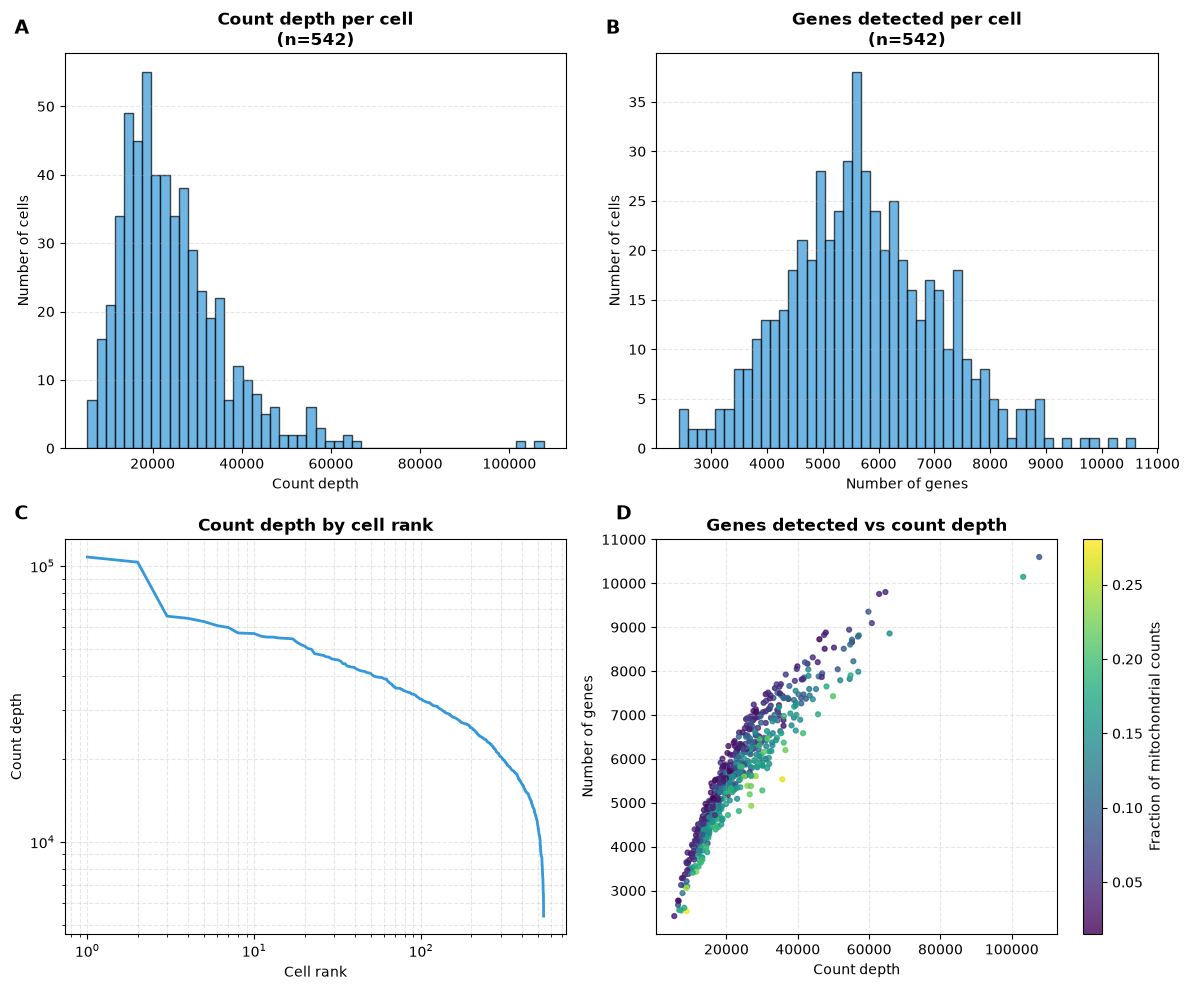

In [6]:
plot_qc_overview(
    raw_data,
    species=SPECIES,
    min_count_threshold=preprocessing_config.min_count_threshold,  # minimum count depth, set in the dataset config
    max_count_threshold=preprocessing_config.max_count_threshold,  # maximum count depth, set in the dataset config
    min_gene_threshold=preprocessing_config.min_gene_threshold,    # minimum genes per cell, set in the dataset config
    max_gene_threshold=preprocessing_config.max_gene_threshold,    # maximum genes per cell, set in the dataset config
)

## Mitochondrial, rRNA and apoptosis fractions

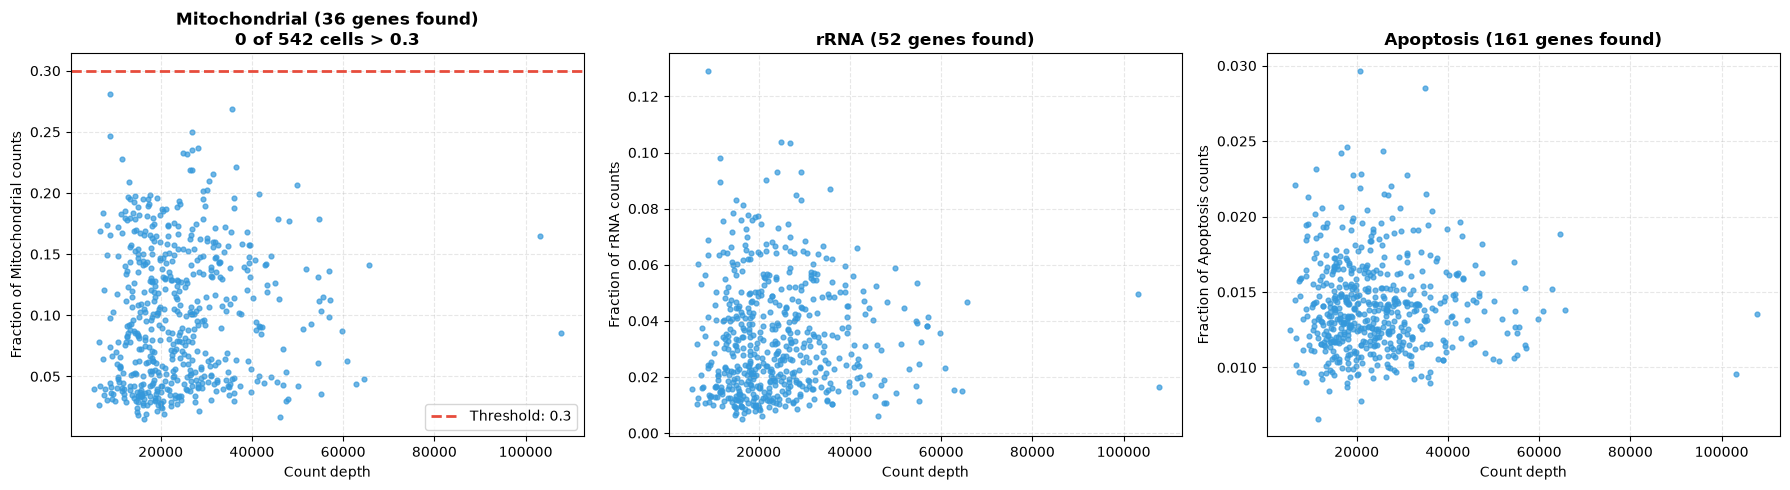

In [7]:
plot_gene_set_qc(raw_data, SPECIES, preprocessing_config)

## Genes

### Uniqueness

In [8]:
duplicates = duplicated_genes(raw_data)

print(f"Gene columns: {raw_data.shape[1]}, unique gene names: {raw_data.columns.nunique()}")
print(f"Gene names appearing in more than one column: {len(duplicates)}")
display(duplicates)

assert duplicates.empty, "Duplicated gene names found, see the table above"

Gene columns: 32044, unique gene names: 32044
Gene names appearing in more than one column: 0


,n_columns,identical_counts
gene,,


### Missing from the annotation

In [9]:
annotation = load_gene_annotation(SPECIES)
unmatched = unmatched_genes(raw_data, annotation)
alias_hits = unmatched.alias_matches
n_alias_genes = alias_hits["gene"].nunique()
n_ambiguous = alias_hits.loc[alias_hits["n_matches"] > 1, "gene"].nunique()

print(f"Genes matching no gene_id or gene_name: {n_alias_genes + len(unmatched.unknown_ensembl_ids) + len(unmatched.other)} / {raw_data.shape[1]}")
print(f"  found through alias_names: {n_alias_genes} ({n_ambiguous} matching more than one annotation row)")
print(f"  Ensembl IDs missing from the annotation: {len(unmatched.unknown_ensembl_ids)}, e.g. {unmatched.unknown_ensembl_ids[:5]}")
print(f"  other: {len(unmatched.other)}, e.g. {unmatched.other[:5]}")
display(alias_hits)

Genes matching no gene_id or gene_name: 658 / 32044
  found through alias_names: 0 (0 matching more than one annotation row)
  Ensembl IDs missing from the annotation: 658, e.g. ['ENSG00000236453', 'ENSG00000271757', 'ENSG00000272567', 'ENSG00000237513', 'ENSG00000262227']
  other: 0, e.g. []


,gene,n_matches,gene_id,gene_name,gene_biotype,chromosome,MT_status,RB_status,TF_status,APOPT_status,alias_names


### rRNA

In [10]:
# Same matching as filter_rrna_genes, so these are exactly the columns the pipeline drops
rrna_columns = matching_genes(raw_data, rrna_genes(SPECIES, annotation))
rrna_counts = raw_data[rrna_columns].sum().sort_values(ascending=False).rename("total_counts")

print(f"rRNA genes filtered out: {len(rrna_columns)} / {raw_data.shape[1]}")
print(f"  share of all counts: {rrna_counts.sum() / raw_data.values.sum():.3f}")
display(rrna_counts.to_frame())

rRNA genes filtered out: 52 / 32044
  share of all counts: 0.034


,total_counts
ENSG00000210082,370004
ENSG00000211459,72359
ENSG00000274917,119
ENSG00000277739,70
ENSG00000273730,65
ENSG00000276700,41
ENSG00000275757,38
ENSG00000278189,32
ENSG00000199804,24
ENSG00000275215,12


## Filtering pipeline

In [11]:
clean_data = run_filtering_pipeline(raw_data, config=preprocessing_config, species=SPECIES)

clean_data.shape

(542, 19728)

### Low expression genes

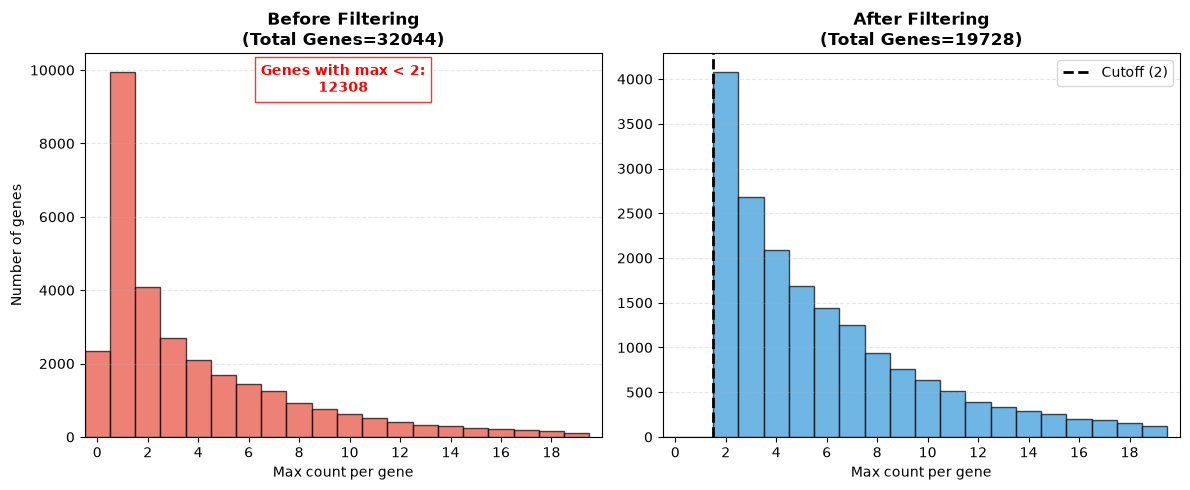

In [12]:
plot_gene_max_count_distribution(raw_data, clean_data, x_limit=20)

## Doublets (demonstration only)

We run the doublet filter to show how many cells it would remove, but the rest of the notebook continues from `clean_data`.

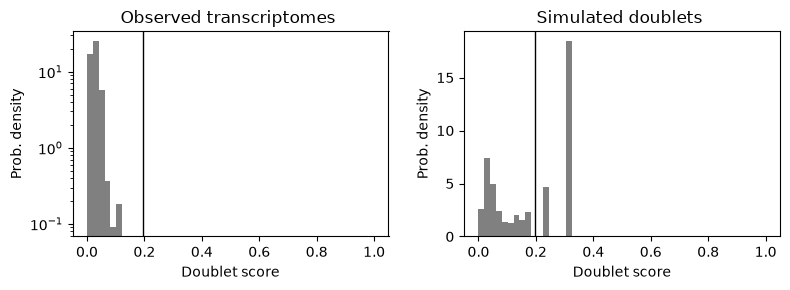

Cells removed as doublets: 0 / 542


In [13]:
# For demonstration only: the rest of the notebook continues from clean_data, not from no_doublets_data
no_doublets_data = filter_doublets(clean_data)

print(f"Cells removed as doublets: {clean_data.shape[0] - no_doublets_data.shape[0]} / {clean_data.shape[0]}")

# Normalization

## logCPM

### Normalize by library size

In [14]:
normalized_data = normalize_by_library_size(clean_data)

normalized_data.shape

(542, 19728)

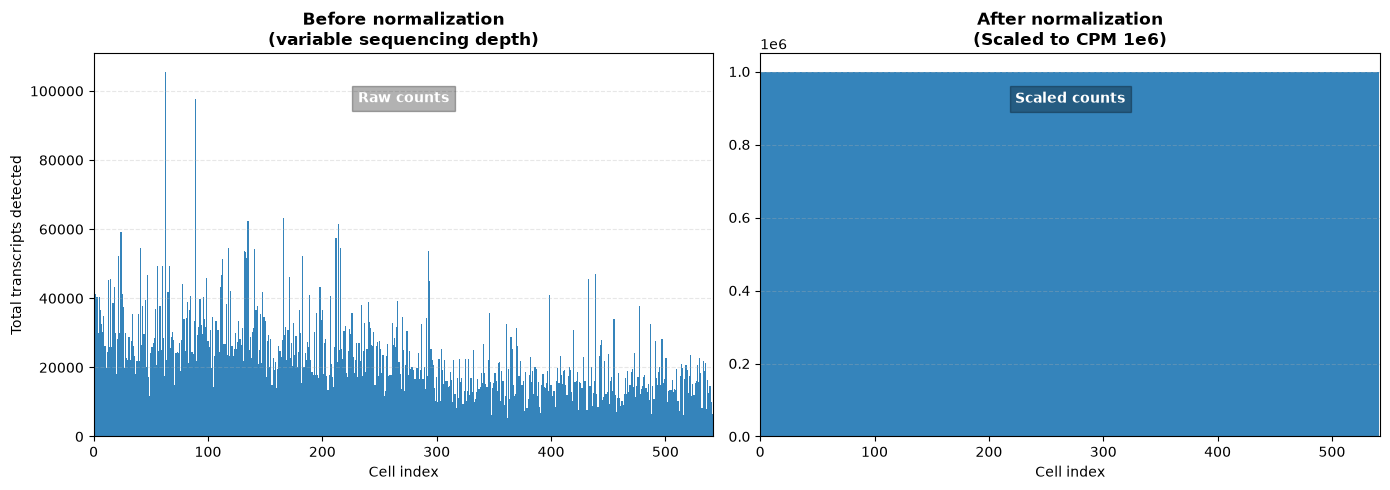

In [15]:
plot_normalization_comparison(clean_data, normalized_data, n_cells=normalized_data.shape[0])

### Log Transform

In [16]:
logged_data = log_transform(normalized_data)

logged_data.shape

(542, 19728)

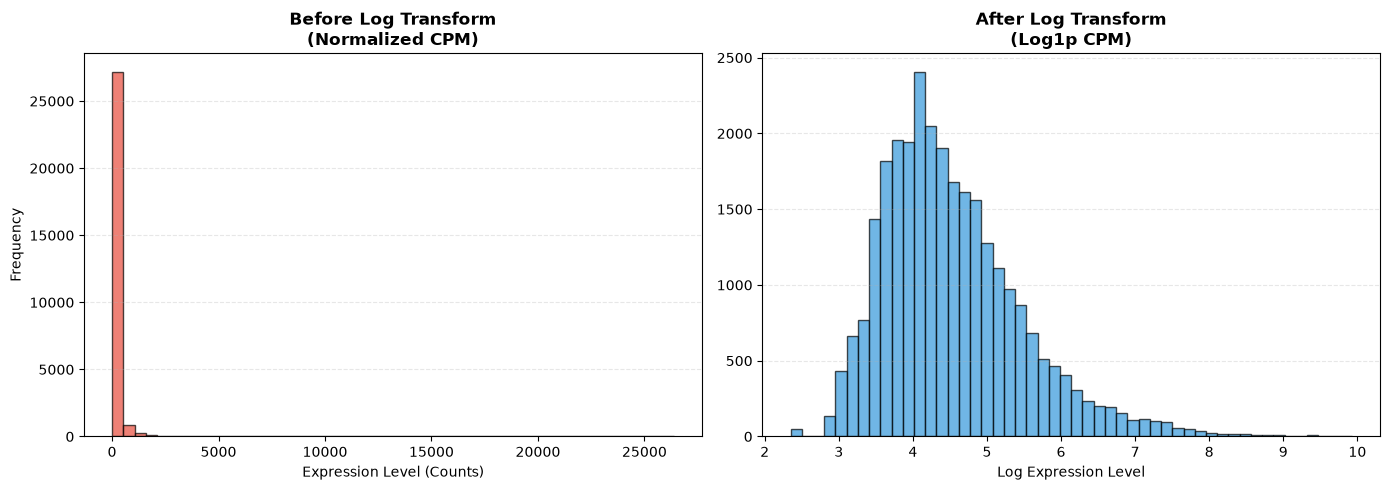

In [17]:
plot_log_transform_comparison(normalized_data, logged_data)

## Pearson residuals

In [18]:
pearsons_data = normalize_with_pearson(clean_data)

pearsons_data.shape

(542, 19728)

In [19]:
pearsons_data.head()

,ENSG00000253629,ENSG00000272866,ENSG00000197826,ENSG00000237513,ENSG00000259915,ENSG00000164841,ENSG00000107317,ENSG00000278873,ENSG00000279063,ENSG00000257595,...,ENSG00000263316,ENSG00000259362,ENSG00000182168,ENSG00000272682,ENSG00000114547,ENSG00000236130,ENSG00000164385,ENSG00000270876,ENSG00000172020,ENSG00000236166
cell_id,,,,,,,,,,,,,,,,,,,,,
p1_A1,-0.073242,-0.089702,-0.103577,-0.089702,-0.103577,-0.073242,-0.115801,-0.115801,-0.073242,-0.073242,...,-0.073242,-0.073242,-0.073242,-0.089702,-0.073242,-0.089702,-0.073242,-0.073242,-0.103577,-0.103577
p1_A14,-0.067453,-0.082612,-0.095391,-0.082612,-0.095391,-0.067453,-0.106649,-0.106649,-0.067453,-0.067453,...,-0.067453,-0.067453,-0.067453,-0.082612,-0.067453,-0.082612,-0.067453,-0.067453,-0.095391,-0.095391
p1_A15,-0.080563,-0.098667,-0.113929,-0.098667,-0.113929,-0.080563,-0.127375,-0.127375,-0.080563,-0.080563,...,-0.080563,-0.080563,-0.080563,-0.098667,-0.080563,-0.098667,-0.080563,-0.080563,-0.113929,-0.113929
p1_A16,-0.079791,-0.097722,-0.112837,-0.097722,-0.112837,-0.079791,-0.126154,-0.126154,-0.079791,-0.079791,...,-0.079791,-0.079791,-0.079791,-0.097722,-0.079791,-0.097722,-0.079791,-0.079791,-0.112837,-0.112837
p1_A19,-0.068523,-0.083923,-0.096904,-0.083923,-0.096904,-0.068523,-0.108341,-0.108341,-0.068523,-0.068523,...,-0.068523,-0.068523,-0.068523,-0.083923,-0.068523,-0.083923,-0.068523,-0.068523,-0.096904,-0.096904
